In [1]:
from huggingface_hub import snapshot_download

# Скачивает все файлы датасета в локальную папку ./lending_club_data
local_dir = snapshot_download(
    repo_id="codesignal/lending-club-loan-accepted",
    repo_type="dataset",
    local_dir="./lending_club_data",
)
print("Файлы сохранены в:", local_dir)

/Users/viktoriabirukova/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 3 files: 100%|██████████| 3/3 [00:00<00:00, 944.03it/s]

Файлы сохранены в: /Users/viktoriabirukova/Desktop/HSE/GP/lending_club_data


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/Users/viktoriabirukova/Desktop/HSE/GP/lending_club_data/accepted_2007_to_2018Q4.csv", low_memory=False)

In [4]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
3,66310712,NaN,35000.0,35000.0,35000.0,60 months,14.85,829.90,C,C5,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


### Описание данных (Lending Club)

| Признак | Описание |
| :--- | :--- |
| **Основные данные по займу и заемщику** | |
| `loan_amnt` / `funded_amnt` | Запрошенная и фактически выданная сумма кредита |
| `term` | Срок кредита (36 или 60 месяцев) |
| `int_rate` | Процентная ставка |
| `installment` | Ежемесячный платеж |
| `grade` / `sub_grade` | Класс кредита (A–G) и подкласс |
| `emp_title` / `emp_length` | Должность и стаж работы заемщика |
| `home_ownership` | Статус жилья (RENT, OWN, MORTGAGE) |
| `annual_inc` | Годовой доход |
| `verification_status` | Статус проверки дохода |
| `issue_d` | Дата выдачи кредита |
| `loan_status` | Текущий статус кредита |
| `purpose` | Цель кредита |
| `addr_state` | Штат заемщика |
| `dti` | Отношение долга к доходу |
| **Кредитная история (начальные данные)** | |
| `delinq_2yrs` | Количество просрочек за 2 года |
| `earliest_cr_line` | Дата открытия первой кредитной линии |
| `inq_last_6mths` | Запросы в кредитное бюро за 6 месяцев |
| `open_acc` | Количество открытых кредитных линий |
| `pub_rec` | Негативные публичные записи |
| `revol_bal` | Баланс по возобновляемым кредитам |
| `revol_util` | Использование возобновляемого кредита |
| `total_acc` | Общее количество кредитных линий |
| `initial_list_status` | Статус первоначального списка (f/w) |
| `application_type` | Тип заявки (Individual / Joint) |
| **История платежей и текущее состояние** | |
| `out_prncp` / `out_prncp_inv` | Остаток основного долга (всего / для инвесторов) |
| `total_pymnt` / `total_pymnt_inv` | Общая сумма платежей (всего / для инвесторов) |
| `total_rec_prncp` | Получено основного долга |
| `total_rec_int` | Получено процентов |
| `total_rec_late_fee` | Получено штрафов за просрочку |
| `recoveries` | Сумма восстановленных средств |
| `collection_recovery_fee` | Комиссия за взыскание |
| `last_pymnt_d` | Дата последнего платежа |
| `last_pymnt_amnt` | Сумма последнего платежа |
| `next_pymnt_d` | Дата следующего платежа |
| `last_credit_pull_d` | Дата последнего запроса кредитной истории |
| `last_fico_range_high` / `low` | Последний диапазон FICO |
| `collections_12_mths_ex_med` | Взыскания за 12 месяцев (кроме мед.) |
| `mths_since_last_major_derog` | Месяцев с последнего серьезного нарушения |
| `policy_code` | Код политики (1 = публичный, 2 = нет) |
| **Дополнительные кредитные метрики (расширенные)** | |
| `acc_now_delinq` | Количество счетов с текущей просрочкой |
| `tot_coll_amt` | Общая сумма взысканий |
| `tot_cur_bal` | Общий текущий баланс |
| `open_acc_6m` | Открытых счетов за 6 месяцев |
| `open_act_il` | Открытых счетов рассрочки |
| `open_il_12m` / `open_il_24m` | Открытых счетов рассрочки за 12/24 мес. |
| `mths_since_rcnt_il` | Месяцев с последнего открытия счета рассрочки |
| `total_bal_il` | Общий баланс по счетам рассрочки |
| `il_util` | Использование счетов рассрочки |
| `open_rv_12m` / `open_rv_24m` | Открытых возобновляемых счетов за 12/24 мес. |
| `max_bal_bc` | Максимальный баланс по банковской карте |
| `all_util` | Общее использование всех кредитов |
| `total_rev_hi_lim` | Общий лимит по возобновляемым кредитам |
| `inq_fi` | Запросы на финансовые продукты |
| `total_cu_tl` | Общее количество кредитных линий в кредитных союзах |
| `inq_last_12m` | Запросы за 12 месяцев |
| `acc_open_past_24mths` | Открытых счетов за последние 24 месяца |
| `avg_cur_bal` | Средний текущий баланс |
| `bc_open_to_buy` | Доступный кредит по банковским картам |
| `bc_util` | Использование банковских карт |
| `chargeoff_within_12_mths` | Списания за 12 месяцев |
| `delinq_amnt` | Сумма просрочки |
| `mo_sin_old_il_acct` | Месяцев с открытия старейшего счета рассрочки |
| `mo_sin_old_rev_tl_op` | Месяцев с открытия старейшего возобновляемого счета |
| `mo_sin_rcnt_rev_tl_op` | Месяцев с открытия последнего возобновляемого счета |
| `mo_sin_rcnt_tl` | Месяцев с открытия последнего счета |
| `mort_acc` | Количество ипотечных счетов |
| `mths_since_recent_bc` | Месяцев с последнего открытия банковской карты |
| `mths_since_recent_bc_dlq` | Месяцев с последней просрочки по банковской карте |
| `mths_since_recent_inq` | Месяцев с последнего запроса |
| `mths_since_recent_revol_delinq` | Месяцев с последней просрочки по возобновляемому кредиту |
| `num_accts_ever_120_pd` | Счетов с просрочкой 120+ дней |
| `num_actv_bc_tl` | Активных банковских карт |
| `num_actv_rev_tl` | Активных возобновляемых счетов |
| `num_bc_sats` | Банковских карт с хорошим статусом |
| `num_bc_tl` | Всего банковских карт |
| `num_il_tl` | Всего счетов рассрочки |
| `num_op_rev_tl` | Открытых возобновляемых счетов |
| `num_rev_accts` | Всего возобновляемых счетов |
| `num_rev_tl_bal_gt_0` | Возобновляемых счетов с балансом > 0 |
| `num_sats` | Счетов с хорошим статусом |
| `num_tl_120dpd_2m` | Счетов с просрочкой 120+ дней за 2 мес. |
| `num_tl_30dpd` | Счетов с просрочкой 30 дней |
| `num_tl_90g_dpd_24m` | Счетов с просрочкой 90+ дней за 24 мес. |
| `num_tl_op_past_12m` | Открытых счетов за 12 месяцев |
| `pct_tl_nvr_dlq` | % счетов без просрочек |
| `percent_bc_gt_75` | % банковских карт с использованием > 75% |
| `pub_rec_bankruptcies` | Публичные записи о банкротстве |
| `tax_liens` | Налоговые залоги |
| `tot_hi_cred_lim` | Общий максимальный кредитный лимит |
| `total_bal_ex_mort` | Общий баланс без ипотеки |
| `total_bc_limit` | Общий лимит банковских карт |
| `total_il_high_credit_limit` | Общий максимальный лимит по рассрочке |
| **Совместные заявки (Joint) и вторичные заемщики (Sec App)** | |
| `annual_inc_joint` | Совместный годовой доход |
| `dti_joint` | Совместный DTI |
| `verification_status_joint` | Статус проверки совместного дохода |
| `revol_bal_joint` | Совместный баланс по возобновляемым кредитам |
| `sec_app_fico_range_low/high` | FICO вторичного заемщика |
| `sec_app_earliest_cr_line` | Первая кредитная линия вторичного заемщика |
| `sec_app_inq_last_6mths` | Запросы вторичного заемщика за 6 мес. |
| `sec_app_mort_acc` | Ипотечные счета вторичного заемщика |
| `sec_app_open_acc` | Открытые счета вторичного заемщика |
| `sec_app_revol_util` | Использование возобновляемых кредитов вторичного заемщика |
| `sec_app_open_act_il` | Открытые счета рассрочки вторичного заемщика |
| `sec_app_num_rev_accts` | Возобновляемые счета вторичного заемщика |
| `sec_app_chargeoff_within_12_mths` | Списания вторичного заемщика за 12 мес. |
| `sec_app_collections_12_mths_ex_med` | Взыскания вторичного заемщика за 12 мес. |
| `sec_app_mths_since_last_major_derog` | Месяцев с последнего нарушения вторичного заемщика |
| **Программа помощи (Hardship) и урегулирование долга** | |
| `hardship_flag` | Флаг программы помощи |
| `hardship_type` | Тип помощи |
| `hardship_reason` | Причина помощи |
| `hardship_status` | Статус помощи |
| `deferral_term` | Срок отсрочки |
| `hardship_amount` | Сумма помощи |
| `hardship_start_date` / `end_date` | Даты начала/окончания помощи |
| `payment_plan_start_date` | Дата начала плана платежей |
| `hardship_length` | Длительность помощи |
| `hardship_dpd` | Просрочка в период помощи |
| `hardship_loan_status` | Статус кредита в период помощи |
| `orig_projected_additional_accrued_interest` | Прогнозируемые дополнительные проценты |
| `hardship_payoff_balance_amount` | Сумма для погашения в рамках помощи |
| `hardship_last_payment_amount` | Сумма последнего платежа в рамках помощи |
| `disbursement_method` | Метод выдачи (Cash, DirectPay) |
| `debt_settlement_flag` | Флаг урегулирования долга |


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2260701 entries, 0 to 2260700
Columns: 151 entries, id to settlement_term
dtypes: float64(113), object(38)
memory usage: 2.5+ GB


In [ ]:
import warnings

# Отключаем предупреждения
warnings.filterwarnings('ignore')

# Загрузка данных
path = "/Users/viktoriabirukova/Desktop/HSE/GP/lending_club_data/accepted_2007_to_2018Q4.csv"
df = pd.read_csv(path, low_memory=False)

# Удаляем колонки
df = df.drop(columns=['id', 'url', 'desc', 'emp_title', 'title'], errors='ignore')

# Чистим 'term'
df['term'] = df['term'].astype(str).str.replace(' months', '', regex=False)
df['term'] = pd.to_numeric(df['term'], errors='coerce')

# Чистим 'emp_length'
emp_map = {'< 1 year': 0.0, '1 year': 1.0, '2 years': 2.0, '3 years': 3.0, '4 years': 4.0, '5 years': 5.0, '6 years': 6.0, '7 years': 7.0, '8 years': 8.0, '9 years': 9.0, '10+ years': 10.0}
df['emp_length'] = df['emp_length'].map(emp_map)

# Чистим ВСЕ даты (включая те, что были пропущены)
date_cols = [
    'issue_d', 'earliest_cr_line', 'last_pymnt_d', 'next_pymnt_d', 'last_credit_pull_d',
    'sec_app_earliest_cr_line', 'hardship_start_date', 'hardship_end_date', 
    'payment_plan_start_date', 'debt_settlement_flag_date', 'settlement_date'
]
for col in date_cols:
    if col in df.columns: # Проверка на всякий случай
        df[col] = pd.to_datetime(df[col], format='mixed', errors='coerce')

print("Очистка завершена. Данные готовы.")

Очистка завершена. Данные готовы.


### Итоги предобработки данных

В ходе подготовки данных были выполнены следующие шаги:

**1. Удалены неинформативные колонки:**
*   `id` — уникальный номер кредита. Не несет информации о том, вернут долг или нет, и может привести к переобучению модели.
*   `url` — ссылка на страницу кредита (бесполезный текст).
*   `desc` и `title` — текстовые описания кредита (свободный текст с шумом и опечатками).
*   `emp_title` — должность заемщика (тысячи уникальных названий, сырой текст).

**2. Очищена колонка `term` (срок кредита):**
*   Убрано слово "months" и пробелы.
*   Значения переведены в числовой формат (`36.0` и `60.0`).

**3. Очищена колонка `emp_length` (стаж работы):**
*   Текстовые значения (например, `"< 1 year"`, `"10+ years"`, `"3 years"`) заменены на числа от `0.0` до `10.0`.

**4. Даты переведены в специальный формат Pandas:**
*   Все колонки с датами сконвертированы в формат `datetime64[ns]` для дальнейшего анализа временных рядов.



In [18]:
df['loan_status'].value_counts(normalize=True)

loan_status
Fully Paid                                             0.476298
Current                                                0.388521
Charged Off                                            0.118796
Late (31-120 days)                                     0.009496
In Grace Period                                        0.003732
Late (16-30 days)                                      0.001924
Does not meet the credit policy. Status:Fully Paid     0.000879
Does not meet the credit policy. Status:Charged Off    0.000337
Default                                                0.000018
Name: proportion, dtype: float64

In [ ]:
# Оставляем только Fully Paid и Charged Off
df_filtered = df[df['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()

#Новая целевая переменная (Target): 
#1 - если кредит возвращен, 0 - если списан
df_filtered['is_default'] = df_filtered['loan_status'].apply(lambda x: 1 if x == 'Fully Paid' else 0)

#Удаляем старую текстовую колонку loan_status, чтобы не мешалась
df_filtered = df_filtered.drop(columns=['loan_status'])

print("Новый размер датафрейма:", df_filtered.shape)
print("\nРаспределение новой целевой переменной (1 - вернул, 0 - не вернул):")
print(df_filtered['is_default'].value_counts(normalize=True))

Новый размер датафрейма: (1345310, 146)

Распределение новой целевой переменной (1 - вернул, 0 - не вернул):
is_default
1    0.800374
0    0.199626
Name: proportion, dtype: float64


### Формирование целевой переменной (Target Variable)

Для перехода к задаче бинарной классификации (предсказание дефолта) из исходного датасета были отфильтрованы кредиты с незавершенным статусом. 

**Итоги:**
1. Оставлены только записи со статусами `Fully Paid` (кредит возвращен) и `Charged Off` (кредит списан).
2. Создана новая бинарная целевая переменная **`is_default`**:
   *   1 - клиент вернул кредит (Fully Paid).
   *   0 - клиент не вернул кредит (Charged Off).
3. Удалена исходная текстовая колонка `loan_status`, чтобы она не мешала обучению модели.

**Результаты после фильтрации:**
*   **Новый размер датафрейма:** 1 345 310 строк, 146 колонок.
*   **Распределение классов:**
    *   1 (Вернул): **80.04%** 
    *   0 (Не вернул): **19.96%**

**Вывод:** 
Наблюдается **дисбаланс классов** (80/20). 

In [22]:
from ydata_profiling import ProfileReport
# (50 000 строк достаточно, чтобы увидеть все закономерности)
df_sample = df_filtered.sample(n=50000, random_state=42)

# Генерация отчета
profile_report_clean = ProfileReport(
    df_sample, 
    title='Pandas Profiling Report (Cleaned Data Sample)', 
    minimal=True  # minimal=True ускоряет генерацию и экономит память
)
profile_report_clean

Render HTML: 100%|██████████| 1/1 [00:01<00:00,  1.33s/it]


In [24]:
profile_report_lending = ProfileReport(df_filtered, title='Lending Club Report', minimal=True)

profile_report_lending.to_file('LendingClub_report.html')

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 87.64it/s]


Доля невозвратов (дефолтов): 20.0%


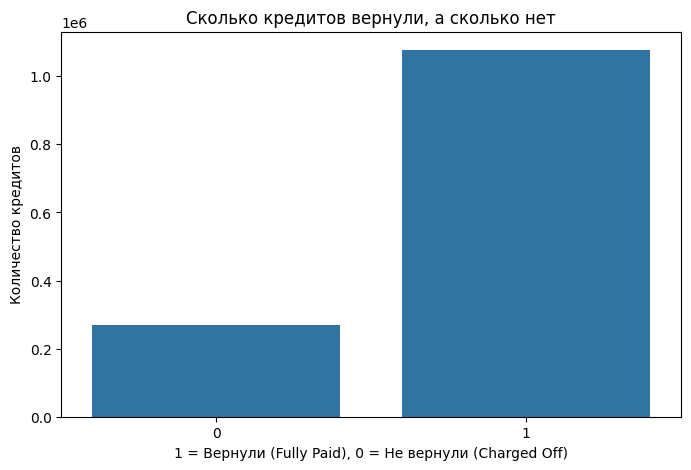

In [30]:
default_rate = (df_filtered['is_default'] == 0).mean()
print(f'Доля невозвратов (дефолтов): {default_rate:.1%}')

plt.figure(figsize=(8, 5))
sns.countplot(data=df_filtered, x='is_default')

plt.title('Сколько кредитов вернули, а сколько нет')
plt.xlabel('1 = Вернули (Fully Paid), 0 = Не вернули (Charged Off)')
plt.ylabel('Количество кредитов')
plt.show()

Наблюдается несбалансированность классов: тех, кто вернул кредит, почти в 4 раза больше, чем тех, кто не вернул (80% против 20%)

In [32]:
#Считаем пропуски 
missing = df_filtered.isna().sum()

#Создаем  табл
missing_df = pd.DataFrame({
    'пропусков': missing,
    'доля, %': (missing / len(df_filtered) * 100).round(1)
})
#Оставляем только те колонки, где пропуски вообще есть, и сортируем по убыванию
missing_df = missing_df[missing_df['пропусков'] > 0].sort_values(by='доля, %', ascending=False)
print(f"Всего колонок с пропусками: {len(missing_df)}")
missing_df.head(20) # Покажем топ-20 самых проблемных колонок

Всего колонок с пропусками: 102


,пропусков,"доля, %"
member_id,1345310,100.0
next_pymnt_d,1345310,100.0
orig_projected_additional_accrued_interest,1341551,99.7
hardship_dpd,1339556,99.6
hardship_type,1339556,99.6
hardship_reason,1339556,99.6
hardship_status,1339556,99.6
deferral_term,1339556,99.6
hardship_amount,1339556,99.6
hardship_start_date,1339556,99.6


In [ ]:
# Находим колонки, где 100% пропусков (все значения NaN)
cols_to_drop = df_filtered.columns[df_filtered.isna().all()].tolist()

df_filtered = df_filtered.drop(columns=cols_to_drop)

print(f"Удалено пустых колонок: {len(cols_to_drop)}")
print(f"Осталось колонок: {df_filtered.shape[1]}")

Удалено пустых колонок: 2
Осталось колонок: 144


In [48]:
# Разумные границы для каждого признака (с запасом)
plausible = {
    'annual_inc': (0, 10000000),        # Годовой доход (от 0 до 10 млн $)
    'int_rate': (0, 40),                # Процентная ставка (до 40%)
    'dti': (0, 100),                    # Debt-to-Income (доля долга от дохода)
    'revol_util': (0, 100),             # Использование кредитных карт (0-100%)
    'open_acc': (0, 50),                # Открытые счета (не больше 50)
    'total_acc': (0, 100),              # Всего счетов (не больше 100)
    'delinq_2yrs': (0, 100)             # Просрочки за 2 года
}

# пустой список для ошибок
errors = []

# значения, которые выходят за рамки
for col, (low, high) in plausible.items():
    if col in df_filtered.columns: # Проверка, есть ли колонка
        bad = df_filtered.loc[(df_filtered[col] < low) | (df_filtered[col] > high), col]
        for row, value in bad.items():
            errors.append({'строка': row, 'признак': col, 'значение': value, 
                           'допустимый диапазон': f'{low} — {high}'})

# табл с ошибками
print(f"Найдено всего подозрительных значений: {len(errors)}")
if len(errors) > 0:
    display(pd.DataFrame(errors).head(10))

Найдено всего подозрительных значений: 5222


,строка,признак,значение,допустимый диапазон
0,8721,dti,999.00,0 — 100
1,10548,dti,137.40,0 — 100
2,22841,dti,100.09,0 — 100
3,55648,dti,120.66,0 — 100
4,66461,dti,380.53,0 — 100
5,73833,dti,672.52,0 — 100
6,77957,dti,125.25,0 — 100
7,97333,dti,104.00,0 — 100
8,421631,dti,112.20,0 — 100
9,423022,dti,531.33,0 — 100


In [49]:
for col, (low, high) in plausible.items():
    if col in df_filtered.columns:
        # Находим индексы, где значения выходят за рамки, и меняем их на NaN
        df_filtered.loc[(df_filtered[col] < low) | (df_filtered[col] > high), col] = np.nan

print("Ошибочные значения заменены на пропуски.")
# Проверяем, сколько пропусков появилось в этих колонках
print(df_filtered[list(plausible.keys())].isna().sum())

Ошибочные значения заменены на пропуски.
annual_inc        0
int_rate          0
dti             535
revol_util     4687
open_acc          0
total_acc         0
delinq_2yrs       0
dtype: int64


In [ ]:

#Заполняем числовые пропуски медианой
numeric_cols = df_filtered.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    median_val = df_filtered[col].median()
    if pd.isna(median_val): median_val = 0 
    df_filtered[col] = df_filtered[col].fillna(median_val)

# Заполняем текстовые пропуски
categorical_cols = df_filtered.select_dtypes(include=['object']).columns
for col in categorical_cols:
    df_filtered[col] = df_filtered[col].fillna('Unknown')

print("Проверка на пропуски:", df_filtered.isna().sum().sum())

Проверка на пропуски (должно быть 0): 7969707


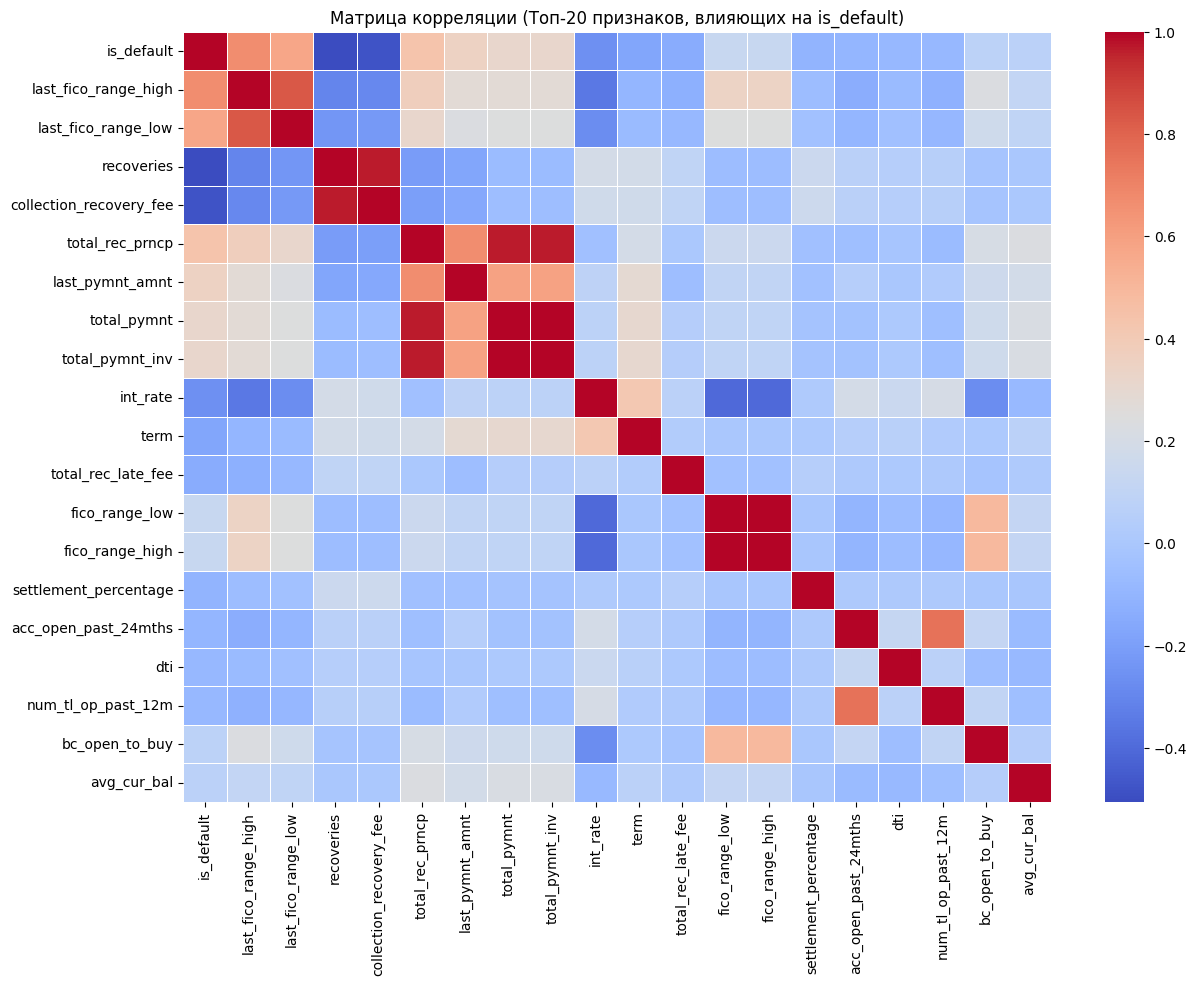

In [ ]:

#Берем только числовые колонки
numeric_df = df_filtered.select_dtypes(include=[np.number])

# 2. Удаляем колонки, где все значения одинаковые (дисперсия = 0) или полные нули
# (например, колонки, которые мы только что заполнили нулями)
numeric_df = numeric_df.loc[:, numeric_df.var() > 0]

#матрица корреляции
corr_matrix = numeric_df.corr()

# Строим график берем топ-20 самых коррелирующих признаков
# Находим 20 признаков с самой высокой корреляцией к нашей целевой переменной
top_corr_features = corr_matrix['is_default'].abs().sort_values(ascending=False).head(20).index
plt.figure(figsize=(14, 10))
sns.heatmap(numeric_df[top_corr_features].corr(), annot=False, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Матрица корреляции (Топ-20 признаков, влияющих на is_default)')
plt.show()

last_fico_range_high и last_fico_range_low: чем выше рейтинг FICO, тем выше вероятность возврата (положительная корреляция). Это надежный признак. (Границы последнего кредитного рейтинга FICO заемщика)

int_rate (Процентная ставка) (синий): Чем выше ставка, тем ниже вероятность возврата. 

term (Срок) (синий): Чем дольше срок (60 месяцев), тем выше риск дефолта.

dti (Долг/Доход) (светло-синий): Чем выше долговая нагрузка, тем выше риск.